In [1]:
# analysis and the question 
# 1. Flights per airline
#2. Busiest airports
#3. Plane turnarounds per airport (same plane landing and leaving again)
#4. Delays in bad weather vs good weather

In [1]:
import os
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

ROOT = "/home/jovyan/project"
RESULTS = ROOT + "/results"
os.makedirs(RESULTS, exist_ok=True)

spark = (SparkSession.builder.appName("dpa-analysis").config("spark.driver.memory", "2g").config("spark.sql.session.timeZone", "UTC").getOrCreate())

spark.read.parquet(ROOT + "/data/clean/flights").createOrReplaceTempView("flights")
spark.read.parquet(ROOT + "/data/clean/airports").createOrReplaceTempView("airports")
spark.read.parquet(ROOT + "/data/joined/flights_weather").createOrReplaceTempView("flights_weather")

In [3]:
# flights per airline

In [2]:
airline_names = [("AA", "American"), ("AS", "Alaska"), ("B6", "JetBlue"), ("DL", "Delta"),
                 ("F9", "Frontier"), ("G4", "Allegiant"), ("HA", "Hawaiian"), ("MQ", "Envoy"),
                 ("NK", "Spirit"), ("OH", "PSA"), ("OO", "SkyWest"), ("UA", "United"),
                 ("WN", "Southwest"), ("YX", "Republic"), ("9E", "Endeavor")]
spark.createDataFrame(airline_names, ["code", "airline"]).createOrReplaceTempView("airline_names")


In [3]:
airlines = spark.sql("""
    SELECT f.Reporting_Airline AS code, COALESCE(n.airline, f.Reporting_Airline) AS airline,
           COUNT(*) AS flights,
           ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_all_flights,
           ROUND(AVG(f.ArrDelay), 1) AS avg_arr_delay,
           ROUND(100 * AVG(f.ArrDel15), 1) AS pct_late_15min
    FROM flights f
    LEFT JOIN airline_names n ON f.Reporting_Airline = n.code
    GROUP BY f.Reporting_Airline, n.airline
    ORDER BY flights DESC
""")
airlines.show(20)

+----+---------+-------+------------------+-------------+--------------+
|code|  airline|flights|pct_of_all_flights|avg_arr_delay|pct_late_15min|
+----+---------+-------+------------------+-------------+--------------+
|  WN|Southwest|2825835|              20.6|          5.5|          21.2|
|  DL|    Delta|1970757|              14.4|          3.0|          16.8|
|  AA| American|1894174|              13.8|         13.8|          24.6|
|  UA|   United|1465850|              10.7|          6.0|          20.2|
|  OO|  SkyWest|1398747|              10.2|          6.0|          17.7|
|  YX| Republic| 581795|               4.2|         -2.6|          13.6|
|  NK|   Spirit| 514471|               3.8|         11.6|          26.5|
|  B6|  JetBlue| 503598|               3.7|         14.9|          28.5|
|  MQ|    Envoy| 500012|               3.6|          5.2|          19.6|
|  AS|   Alaska| 482966|               3.5|          3.5|          20.8|
|  OH|      PSA| 414745|               3.0|        

In [4]:
airlines.toPandas().to_csv(RESULTS + "/flights_per_airline.csv", index=False)

In [6]:
# busiest airport 
# airport traffic = flights leaving it + flights arriving at it

In [5]:
airports_traffic = spark.sql("""
    SELECT t.airport, a.name, a.iso_region AS state,
           SUM(t.departures) AS departures, SUM(t.arrivals) AS arrivals,
           SUM(t.departures + t.arrivals) AS total_flights,
           COUNT(DISTINCT t.airline) AS airlines
    FROM (
        SELECT Origin AS airport, Reporting_Airline AS airline, 1 AS departures, 0 AS arrivals FROM flights
        UNION ALL
        SELECT Dest AS airport, Reporting_Airline AS airline, 0 AS departures, 1 AS arrivals FROM flights
    ) t
    LEFT JOIN airports a ON t.airport = a.iata_code
    GROUP BY t.airport, a.name, a.iso_region
    ORDER BY total_flights DESC
""")
airports_traffic.show(20, truncate=False)


+-------+---------------------------------------------------------------------+-----+----------+--------+-------------+--------+
|airport|name                                                                 |state|departures|arrivals|total_flights|airlines|
+-------+---------------------------------------------------------------------+-----+----------+--------+-------------+--------+
|ATL    |Hartsfield Jackson Atlanta International Airport                     |US-GA|670597    |670625  |1341222      |13      |
|DEN    |Denver International Airport                                         |US-CO|588523    |587602  |1176125      |11      |
|DFW    |Dallas Fort Worth International Airport                              |US-TX|586893    |585955  |1172848      |12      |
|ORD    |Chicago O'Hare International Airport                                 |US-IL|530576    |529930  |1060506      |12      |
|CLT    |Charlotte Douglas International Airport                              |US-NC|406947    |4

In [6]:
airports_traffic.limit(50).toPandas().to_csv(RESULTS + "/busiest_airports.csv", index=False)

In [9]:
# Plane turnarounds per airport

# following plane Tail_Number through the day. turnaround is when a plane lands at an airport and its next flight leaves from that same airport on the same day.
#For each airport we count the turnarounds, the average time on the ground and how late the next flight leaves when the plane arrived late or on time
# this shows whether delays are passed on to the next flight.

In [7]:
spark.sql("""
    SELECT Tail_Number, FlightDate, Dest AS airport, CRSArrTime, ArrDelay,
           LEAD(Origin) OVER w AS next_origin,
           LEAD(FlightDate) OVER w AS next_date,
           LEAD(CRSDepTime) OVER w AS next_dep_time,
           LEAD(DepDelay) OVER w AS next_dep_delay
    FROM flights
    WINDOW w AS (PARTITION BY Tail_Number ORDER BY FlightDate, CRSDepTime)
""").createOrReplaceTempView("next_flights")

In [8]:
# time on the ground in minutes = next departure time - arrival time (both "hhmm")
turnarounds = spark.sql("""
    SELECT *,
           (INT(SUBSTR(next_dep_time, 1, 2)) * 60 + INT(SUBSTR(next_dep_time, 3, 2)))
         - (INT(SUBSTR(CRSArrTime, 1, 2)) * 60 + INT(SUBSTR(CRSArrTime, 3, 2))) AS ground_minutes
    FROM next_flights
    WHERE next_origin = airport AND next_date = FlightDate
""").filter("ground_minutes > 0")
turnarounds.createOrReplaceTempView("turnarounds")

In [9]:
turnaround_airports = spark.sql("""
    SELECT airport,
           COUNT(*) AS turnarounds,
           ROUND(AVG(ground_minutes), 0) AS avg_ground_minutes,
           ROUND(AVG(CASE WHEN ArrDelay > 15 THEN next_dep_delay END), 1) AS next_dep_delay_if_arrived_late,
           ROUND(AVG(CASE WHEN ArrDelay <= 15 THEN next_dep_delay END), 1) AS next_dep_delay_if_on_time
    FROM turnarounds
    GROUP BY airport
    ORDER BY turnarounds DESC
""")
turnaround_airports.show(20)


+-------+-----------+------------------+------------------------------+-------------------------+
|airport|turnarounds|avg_ground_minutes|next_dep_delay_if_arrived_late|next_dep_delay_if_on_time|
+-------+-----------+------------------+------------------------------+-------------------------+
|    ATL|     551733|             103.0|                          45.5|                      3.9|
|    DEN|     482455|              78.0|                          47.0|                      5.1|
|    DFW|     470418|              97.0|                          43.5|                      5.3|
|    ORD|     412439|              87.0|                          43.3|                      3.5|
|    CLT|     343084|              94.0|                          47.3|                      5.2|
|    LAS|     295784|              66.0|                          50.0|                      4.2|
|    PHX|     289697|              78.0|                          41.3|                      3.2|
|    LAX|     275118

In [10]:
turnaround_airports.limit(50).toPandas().to_csv(RESULTS + "/turnarounds_per_airport.csv", index=False)

In [14]:
# delay in bad weather

In [11]:
weather_delay = spark.sql("""
    SELECT bad_weather,
           COUNT(*) AS flights,
           ROUND(AVG(DepDelay), 1) AS avg_dep_delay,
           ROUND(AVG(ArrDelay), 1) AS avg_arr_delay,
           ROUND(100 * AVG(CASE WHEN DepDelay > 15 THEN 1 ELSE 0 END), 1) AS pct_dep_late_15min
    FROM flights_weather
    GROUP BY bad_weather
""")
weather_delay.show()


+-----------+-------+-------------+-------------+------------------+
|bad_weather|flights|avg_dep_delay|avg_arr_delay|pct_dep_late_15min|
+-----------+-------+-------------+-------------+------------------+
|       true| 788554|         20.3|         17.7|              26.6|
|      false|9946012|         12.2|          6.2|              20.2|
+-----------+-------+-------------+-------------+------------------+



In [12]:
weather_delay.toPandas().to_csv(RESULTS + "/delay_bad_vs_good_weather.csv", index=False)

In [17]:
# cheking which type of bad weather effect most

In [13]:
weather_type = spark.sql("""
    SELECT CASE WHEN visibility < 4828 THEN 'low visibility'
                WHEN ceiling < 305 THEN 'low clouds'
                WHEN wind_speed >= 10.3 THEN 'strong wind'
                WHEN rain >= 2.5 THEN 'heavy rain'
                ELSE 'good weather' END AS weather,
           COUNT(*) AS flights,
           ROUND(AVG(DepDelay), 1) AS avg_dep_delay,
           ROUND(100 * AVG(CASE WHEN DepDelay > 15 THEN 1 ELSE 0 END), 1) AS pct_dep_late_15min
    FROM flights_weather
    GROUP BY 1
    ORDER BY avg_dep_delay DESC
""")
weather_type.show()


+--------------+-------+-------------+------------------+
|       weather|flights|avg_dep_delay|pct_dep_late_15min|
+--------------+-------+-------------+------------------+
|    heavy rain|  63656|         45.6|              47.3|
|low visibility| 270960|         22.4|              27.8|
|   strong wind| 135344|         21.9|              30.0|
|    low clouds| 318594|         12.9|              20.0|
|  good weather|9946012|         12.2|              20.2|
+--------------+-------+-------------+------------------+



In [14]:
weather_type.toPandas().to_csv(RESULTS + "/delay_by_weather_type.csv", index=False)

In [20]:
# effect of bad weather per airport

In [15]:
weather_airports = spark.sql("""
    SELECT Origin AS airport, origin_name,
           COUNT(*) AS flights,
           ROUND(AVG(CASE WHEN NOT bad_weather THEN DepDelay END), 1) AS delay_good_weather,
           ROUND(AVG(CASE WHEN bad_weather THEN DepDelay END), 1) AS delay_bad_weather
    FROM flights_weather
    GROUP BY Origin, origin_name
""").withColumn("extra_delay", F.round(F.col("delay_bad_weather") - F.col("delay_good_weather"), 1))

weather_airports.orderBy(F.desc("extra_delay")).show(50, truncate=False)

+-------+---------------------------------------------------------------------+-------+------------------+-----------------+-----------+
|airport|origin_name                                                          |flights|delay_good_weather|delay_bad_weather|extra_delay|
+-------+---------------------------------------------------------------------+-------+------------------+-----------------+-----------+
|MIA    |Miami International Airport                                          |208381 |18.4              |47.8             |29.4       |
|FLL    |Fort Lauderdale Hollywood International Airport                      |177797 |19.0              |45.2             |26.2       |
|RSW    |Southwest Florida International Airport                              |66274  |11.9              |31.7             |19.8       |
|MCO    |Orlando International Airport                                        |317205 |17.0              |35.8             |18.8       |
|LAS    |Harry Reid International Airport

In [16]:
weather_airports.toPandas().to_csv(RESULTS + "/weather_effect_per_airport.csv", index=False)

In [23]:
# ploting the charts

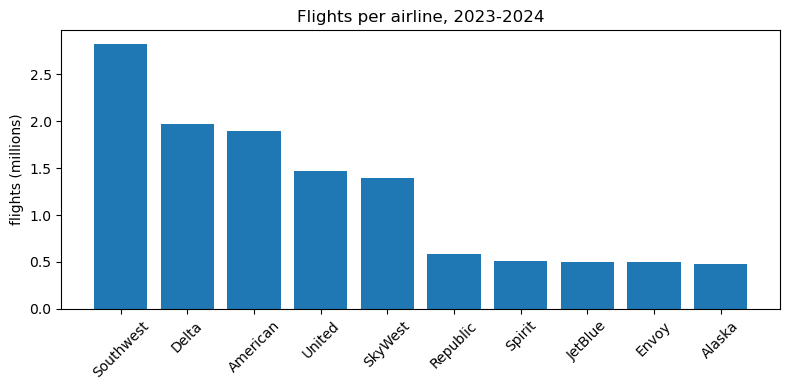

In [18]:
top_airlines = airlines.limit(10).toPandas()
plt.figure(figsize=(8, 4))
plt.bar(top_airlines["airline"], top_airlines["flights"] / 1e6)
plt.ylabel("flights (millions)")
plt.title("Flights per airline, 2023-2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(RESULTS + "/chart_airlines.png", dpi=150)
plt.show()

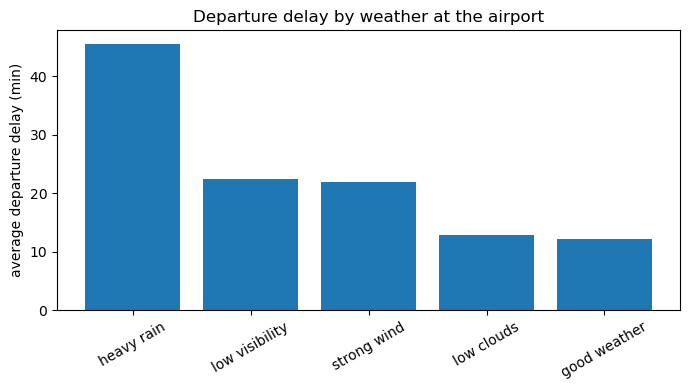

In [19]:
wt = weather_type.toPandas()
plt.figure(figsize=(7, 4))
plt.bar(wt["weather"], wt["avg_dep_delay"])
plt.ylabel("average departure delay (min)")
plt.title("Departure delay by weather at the airport")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(RESULTS + "/chart_weather.png", dpi=150)
plt.show()

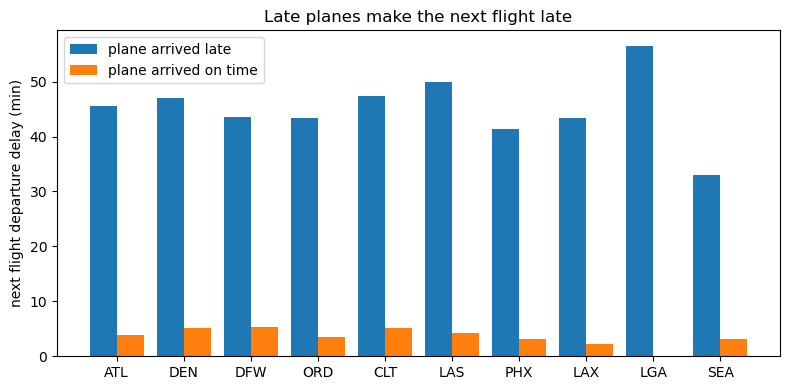

In [20]:
# next flight delay when the plane arrived late vs on time (10 airports with the most turnarounds)
ta = turnaround_airports.limit(10).toPandas()
x = range(len(ta))
plt.figure(figsize=(8, 4))
plt.bar([i - 0.2 for i in x], ta["next_dep_delay_if_arrived_late"], width=0.4, label="plane arrived late")
plt.bar([i + 0.2 for i in x], ta["next_dep_delay_if_on_time"], width=0.4, label="plane arrived on time")
plt.xticks(x, ta["airport"])
plt.ylabel("next flight departure delay (min)")
plt.title("Late planes make the next flight late")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS + "/chart_turnarounds.png", dpi=150)
plt.show()

In [23]:
spark.stop()